# Analytics Report & Insights: Retail Profitability Review
**AI ML Research Specialist Internship — Task 5** · Submitted by: Pranav

This notebook is the analysis behind the written report (`Analytics_Report_Pranav.docx`). Each finding below is a sentence computed from the data, so the text cannot drift from the numbers.

## 1. Business Objectives
**Scenario.** I act as an analyst for a US retailer of office supplies, furniture and technology. Leadership has noticed that in the latest year sales grew strongly but profit grew more slowly, and has asked for a performance review.

**Stakeholders:** the VP of Sales and regional sales leaders (decide on discounting and pricing), operations (shipping, returns), and finance (margin targets).

**Business question:** *Where is the company making and losing money, why, and what should it do first?*

| # | Key question | Section |
|---|---|---|
| Q1 | How has the business performed, and is profit keeping up with sales? | 4 |
| Q2 | Which discount levels, products and places are leaking profit? | 5, 6 |
| Q3 | What changed in the latest year? | 7 |
| Q4 | Which customers and segments matter most? | 8 |
| Q5 | Are there seasonal, shipping or return issues needing attention? | 9, 10 |
| Q6 | What should the business do, in what order, and what is it worth? | 11, 12 |

**Data:** the *Superstore* sample dataset published with Tableau (a fictional retailer; ~10,000 order lines dated 2015–2018), downloaded from a public GitHub repository: `https://github.com/leonism/sample-superstore`. Profit is as supplied (no cost data is available to rebuild it). Because the company is fictional, the figures illustrate an analysis, not a real business.

**Key definitions:** *Margin* = profit ÷ sales. *Heavily discounted line* = an order line with discount above 20%. *Order line* = one product on one order.

## 2. Setup

In [1]:
import inspect, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
import superstore_lib as L
warnings.filterwarnings("ignore"); L.style()
pd.set_option("display.width", 140, "display.max_columns", 30)
show = lambda text: display(Markdown(text))
SRC = "superstore.csv"
URL = "https://raw.githubusercontent.com/leonism/sample-superstore/master/data/superstore.csv"
import os
if not os.path.exists(SRC): pd.read_csv(URL).to_csv(SRC, index=False)

## 3. Data Loading, Structure Check and Cleaning

The raw file has 10,800 rows, more than the 9,994 order lines I expected. Looking at the end of the file shows why.

In [2]:
raw = L.load_raw(SRC)
print("Raw file:", raw.shape)
raw.iloc[9992:10003, :4]

Raw file: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date
9992,9993,CA-2018-121258,2/26/2018,3/3/2018
9993,9994,CA-2018-119914,5/4/2018,5/9/2018
9994,Person,Region,NaN,NaN
9995,Anna Andreadi,West,NaN,NaN
9996,Chuck Magee,East,NaN,NaN
9997,Kelly Williams,Central,NaN,NaN
9998,Cassandra Brandow,South,NaN,NaN
9999,Returned,Order ID,NaN,NaN
10000,Yes,CA-2015-100762,NaN,NaN
10001,Yes,CA-2015-100762,NaN,NaN


In [3]:
lines, returns, managers = L.split_raw(raw)
print("Order lines          :", len(lines))
print("Appended returns rows:", len(returns), "->", returns.nunique(), "distinct returned orders")
print("Appended managers    :", managers.to_dict("records"))

Order lines          : 9994
Appended returns rows: 800 -> 296 distinct returned orders
Appended managers    : [{'manager': 'Anna Andreadi', 'region': 'West'}, {'manager': 'Chuck Magee', 'region': 'East'}, {'manager': 'Kelly Williams', 'region': 'Central'}, {'manager': 'Cassandra Brandow', 'region': 'South'}]


**Finding:** the CSV contains three tables stacked together: the order lines, a short list of regional managers, and a returns list (one row per returned order line). A naive load would count these 806 rows as sales with blank values, so I split them apart first. The returns list is useful: it lets me measure returns, which the sales table alone does not.

In [4]:
d = L.clean(lines, returns)
print("Clean order lines:", d.shape)
print("Missing values per column (only columns with gaps):")
print(d.isna().sum()[lambda s: s > 0])
print("Duplicate order lines (all columns except row id):", d.drop(columns="row_id").duplicated().sum())
checks = pd.Series(L.validation_checks(d), name="passed").to_frame()
checks["passed"] = checks["passed"].map({True: "PASS", False: "FAIL"}); checks

Clean order lines: (9994, 29)
Missing values per column (only columns with gaps):
postal_code    11
dtype: int64
Duplicate order lines (all columns except row id): 1


,passed
Row IDs unique,PASS
Sales > 0,PASS
Quantity >= 1,PASS
Discount between 0 and 1,PASS
Ship date on/after order date,PASS
Order-ID year matches order date,PASS
Each order has one customer,PASS
Each order has one region,PASS


**Cleaning decisions**
- **Stacked tables:** split into order lines (9,994), returns (800 lines / 296 orders) and managers (4 rows).
- **Types:** dates parsed (`month/day/year`), `quantity` and `row_id` converted to integers.
- **Missing values:** only `postal_code` is missing (11 lines, all in one city); it is not used in this analysis, so it is left as missing rather than guessed.
- **Duplicates:** none among the order lines (one line repeats another in every field except the row id, which is a plausible repeat purchase and is kept).
- **Derived fields:** year, month, shipping days, returned flag, discount band, loss-making flag.
- **Validation:** eight business-rule checks all pass (sales positive, discounts between 0 and 1, ship date not before order date, each order has one customer and one region, and so on).

In [5]:
d.to_csv("superstore_clean.csv", index=False)
T = L.tables(d)
d[["order_id", "order_date", "customer_id", "region", "category", "sub_category", "sales", "quantity", "discount", "profit", "returned"]].head()

,order_id,order_date,customer_id,region,category,sub_category,sales,quantity,discount,profit,returned
0,CA-2017-152156,2017-11-08,CG-12520,South,Furniture,Bookcases,261.9600,2,0.00,41.9136,False
1,CA-2017-152156,2017-11-08,CG-12520,South,Furniture,Chairs,731.9400,3,0.00,219.5820,False
2,CA-2017-138688,2017-06-12,DV-13045,West,Office Supplies,Labels,14.6200,2,0.00,6.8714,False
3,US-2016-108966,2016-10-11,SO-20335,South,Furniture,Tables,957.5775,5,0.45,-383.0310,False
4,US-2016-108966,2016-10-11,SO-20335,South,Office Supplies,Storage,22.3680,2,0.20,2.5164,False


## 4. Q1: How Is the Business Performing?

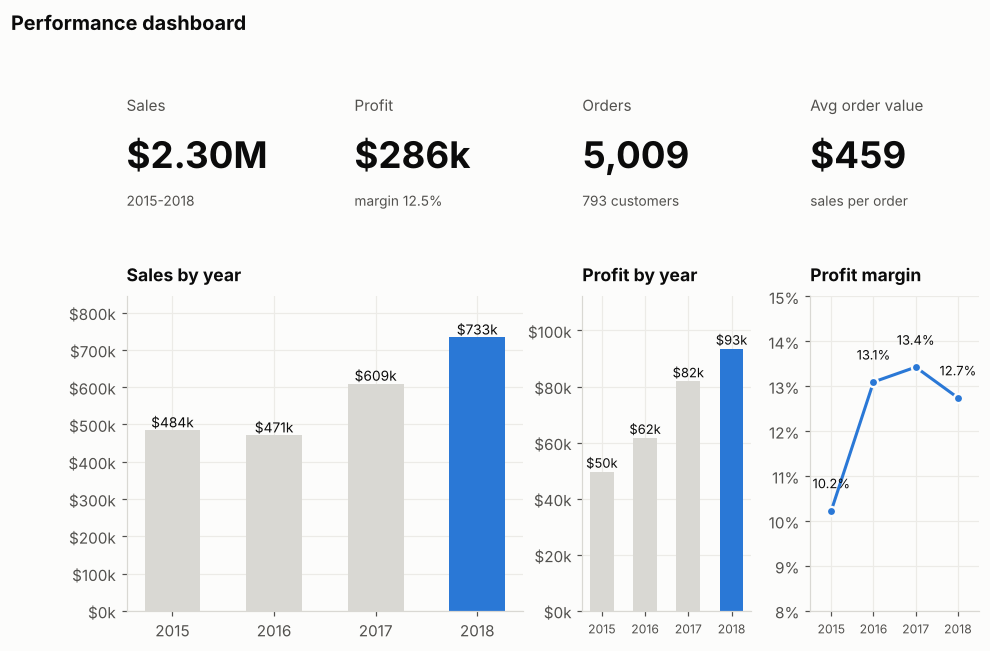

,sales,profit,margin,orders,customers,sales_growth,profit_growth
year,,,,,,,
2015,484247.498,49543.974,0.102,969,595,NaN,NaN
2016,470532.509,61618.604,0.131,1038,573,-0.028,0.244
2017,609205.598,81795.174,0.134,1315,638,0.295,0.327
2018,733215.255,93439.270,0.127,1687,693,0.204,0.142


**Finding:** over 2015-2018 the company sold **$2,297,201** across 5,009 orders from 793 customers, earning **$286,397** profit (margin 12.5%). In 2018 sales grew **20.4%** but profit only **14.2%**, so margin slipped from 13.4% to 12.7%.

In [6]:
fig = L.fig_dashboard(T); plt.show()
y = T["yearly"]
display(y[["sales", "profit", "margin", "orders", "customers", "sales_growth", "profit_growth"]].round(3))
kp = T["kpi"]
show(f"**Finding:** over {kp['first']:%Y}-{kp['last']:%Y} the company sold **{L.money(kp['sales'])}** across {kp['orders']:,} orders from {kp['customers']} customers, earning **{L.money(kp['profit'])}** profit (margin {L.pct(kp['margin'])}). "
     f"In {int(y.index[-1])} sales grew **{L.pct(y['sales_growth'].iloc[-1])}** but profit only **{L.pct(y['profit_growth'].iloc[-1])}**, so margin slipped from {L.pct(y['margin'].iloc[-2])} to {L.pct(y['margin'].iloc[-1])}.")

## 5. Q2a: Where Is Profit Leaking? Discounts

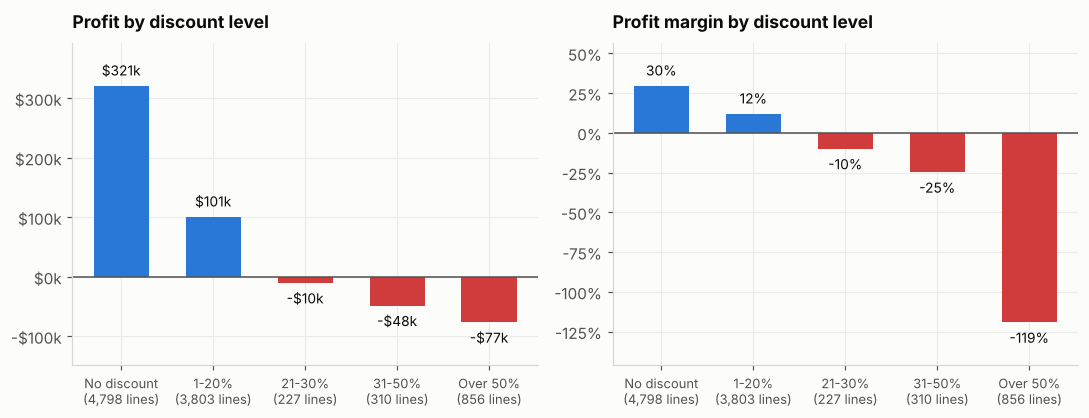

,lines,share_of_lines,sales,profit,margin
disc_band,,,,,
No discount,4798,0.480,1087908.470,320987.603,0.295
1-20%,3803,0.381,846522.240,100785.474,0.119
21-30%,227,0.023,103226.655,-10369.277,-0.100
31-50%,310,0.031,195314.757,-48447.727,-0.248
Over 50%,856,0.086,64228.738,-76559.051,-1.192


**Finding:** profit falls as discounts deepen. Lines with no discount earn a 29.5% margin and lines up to 20% off earn 11.9%, but every band above 20% loses money, reaching **-119.2%** above 50% off. The 1,393 heavily discounted lines are only 13.9% of lines and 15.8% of sales, yet they lost **$135,376**, equal to 47% of total profit. 89% of all losses on loss-making lines come from them.

In [7]:
fig = L.fig_discount(T); plt.show()
b = T["band"].copy(); b["share_of_lines"] = b["lines"] / b["lines"].sum()
display(b[["lines", "share_of_lines", "sales", "profit", "margin"]].round(3))
h, ll = T["hd_total"], T["loss_lines"]
show(f"**Finding:** profit falls as discounts deepen. Lines with no discount earn a {L.pct(T['band'].loc['No discount','margin'])} margin and lines up to 20% off earn {L.pct(T['band'].loc['1-20%','margin'])}, "
     f"but every band above 20% loses money, reaching **{L.pct(T['band'].loc['Over 50%','margin'])}** above 50% off. "
     f"The {h['lines']:,} heavily discounted lines are only {L.pct(h['lines_share'])} of lines and {L.pct(h['sales_share'])} of sales, yet they lost **{L.money(-h['profit'])}**, equal to {L.pct(-h['profit']/kp['profit'],0)} of total profit. "
     f"{L.pct(ll['share_from_high_disc'],0)} of all losses on loss-making lines come from them.")

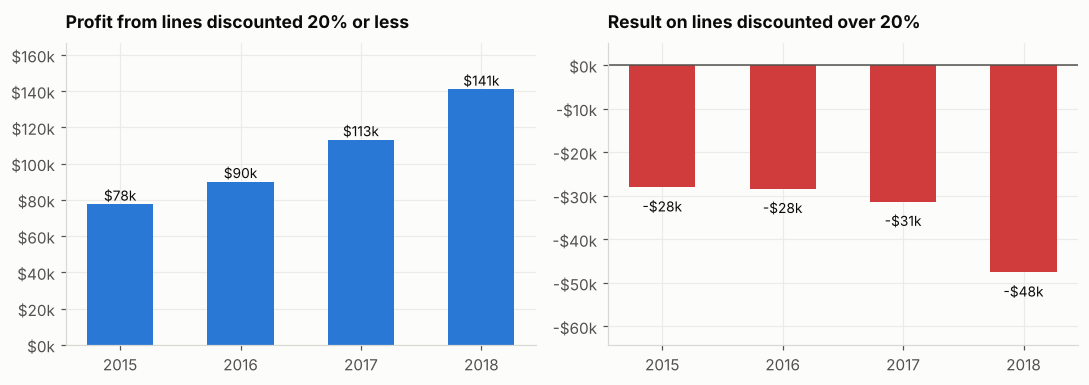

,hd_lines,hd_lines_share,hd_profit,profit_ex_hd
year,,,,
2015,282,0.141,-28043.878,77587.852
2016,293,0.139,-28405.164,90023.768
2017,363,0.140,-31357.113,113152.288
2018,455,0.137,-47569.900,141009.169


**Finding:** profit from lines discounted 20% or less grew 24.6% in 2018, but losses on heavily discounted lines grew 51.7% (-$31.4k to -$47.6k). The number of heavily discounted lines rose from 363 to 455 and each lost more.

In [8]:
fig = L.fig_hd_trend(T); plt.show()
cols = ["hd_lines", "hd_lines_share", "hd_profit", "profit_ex_hd"]
display(T["yearly"][cols].round(3))
y = T["yearly"]; a, z = y.index[-2], y.index[-1]
show(f"**Finding:** profit from lines discounted 20% or less grew {L.pct(y.loc[z,'profit_ex_hd']/y.loc[a,'profit_ex_hd']-1)} in {z}, but losses on heavily discounted lines grew {L.pct(y.loc[z,'hd_profit']/y.loc[a,'hd_profit']-1)} "
     f"({L.k(y.loc[a,'hd_profit'])} to {L.k(y.loc[z,'hd_profit'])}). The number of heavily discounted lines rose from {int(y.loc[a,'hd_lines'])} to {int(y.loc[z,'hd_lines'])} and each lost more.")

## 6. Q2b: Which Products and Places?

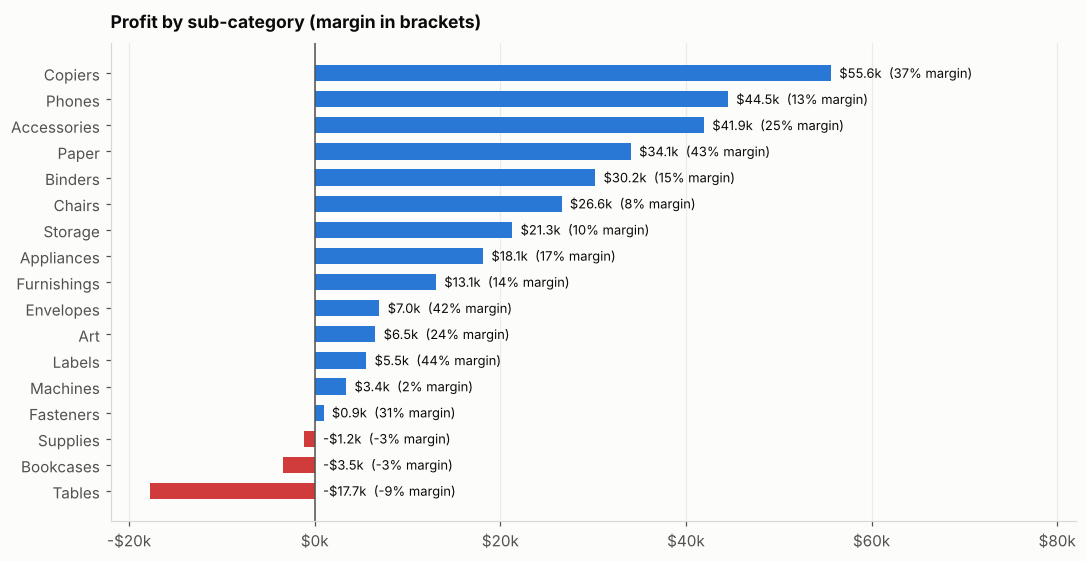

,profit_normal,profit_high_disc,hd_lines_share,sales,profit,margin
sub_category,,,,,,
Binders,68732.26,-38510.50,0.40,203412.73,30221.76,0.15
Tables,12972.74,-30698.22,0.55,206965.53,-17725.48,-0.09
Machines,32940.11,-29555.35,0.46,189238.63,3384.76,0.02
Bookcases,7625.21,-11097.76,0.31,114880.00,-3472.56,-0.03
Appliances,26767.65,-8629.64,0.14,107532.16,18138.01,0.17
Chairs,33327.28,-6737.12,0.26,328449.10,26590.17,0.08


**Finding:** three sub-categories are loss-making overall: Tables (-$17.7k), Bookcases (-$3.5k), Supplies (-$1.2k). But the larger point is that the problem is the discount, not the product. Binders, Tables, Machines each earn a profit at normal discounts ($68.7k, $13.0k, $32.9k) and lose heavily on lines discounted over 20% (-$38.5k, -$30.7k, -$29.6k). Together those three account for 73% of all losses from heavy discounting.

In [9]:
fig = L.fig_subcat(T); plt.show()
sd = T["subcat_disc"].join(T["subcat"][["sales", "profit", "margin"]]).sort_values("profit_high_disc")
display(sd.head(6).round(2))
top3 = sd.head(3); share3 = top3["profit_high_disc"].sum() / T["hd_total"]["profit"]
show(f"**Finding:** three sub-categories are loss-making overall: " + ", ".join(f"{n} ({L.k(r['profit'])})" for n, r in T['subcat'].head(3).iterrows()) + ". "
     f"But the larger point is that the problem is the discount, not the product. {', '.join(top3.index)} each earn a profit at normal discounts "
     f"({', '.join(L.k(v) for v in top3['profit_normal'])}) and lose heavily on lines discounted over 20% ({', '.join(L.k(v) for v in top3['profit_high_disc'])}). "
     f"Together those three account for {L.pct(share3,0)} of all losses from heavy discounting.")

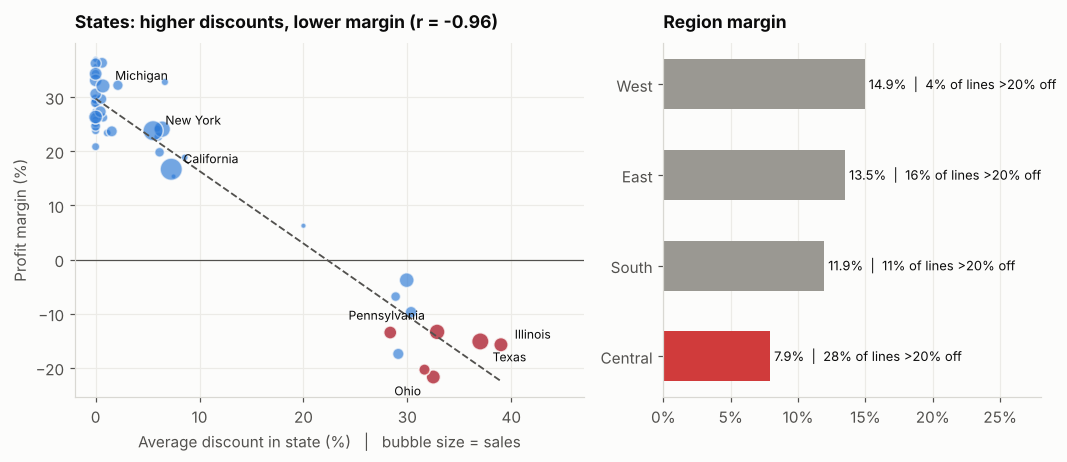

,sales,profit,avg_discount,margin
state,,,,
Texas,170188.046,-25729.356,0.370,-0.151
Ohio,78258.136,-16971.377,0.325,-0.217
Pennsylvania,116511.914,-15559.960,0.329,-0.134
Illinois,80166.101,-12607.887,0.390,-0.157
North Carolina,55603.164,-7490.912,0.284,-0.135
Colorado,32108.118,-6527.858,0.316,-0.203
Tennessee,30661.873,-5341.694,0.291,-0.174
Arizona,35282.001,-3427.925,0.304,-0.097
Florida,89473.708,-3399.302,0.299,-0.038


**Finding:** 10 states lose money, with combined sales of $705,684 (31% of the total) and a combined loss of **$98,247**. State-level average discount and margin are almost perfectly inversely related (r = -0.96). The 10 states averaging more than 25% discount are exactly the 10 loss-making states; no profitable state averages more than 20% discount. Central region has the lowest margin (7.9%) and the highest share of heavily discounted lines (28%, against 4% in the West). Note that the states form two clusters (low-discount and high-discount), so the correlation shows a strong pattern, not a smooth dose-response.

In [10]:
fig = L.fig_geo(T); plt.show()
st = T["state"]; neg = st[st["profit"] < 0]
display(neg[["sales", "profit", "avg_discount", "margin"]].round(3))
hi = st[st["avg_discount"] > 0.25]
show(f"**Finding:** {len(neg)} states lose money, with combined sales of {L.money(neg['sales'].sum())} ({L.pct(neg['sales'].sum()/kp['sales'],0)} of the total) and a combined loss of **{L.money(-neg['profit'].sum())}**. "
     f"State-level average discount and margin are almost perfectly inversely related (r = {T['state_corr']:.2f}). The {len(hi)} states averaging more than 25% discount are exactly the {len(neg)} loss-making states" + ("" if set(hi.index)==set(neg.index) else " (with exceptions)") + f"; no profitable state averages more than {L.pct(st.loc[~st.index.isin(neg.index),'avg_discount'].max(),0)} discount. "
     f"Central region has the lowest margin ({L.pct(T['region'].loc['Central','margin'])}) and the highest share of heavily discounted lines ({L.pct(T['region'].loc['Central','hd_lines_share'],0)}, against {L.pct(T['region'].loc['West','hd_lines_share'],0)} in the West). "
     f"Note that the states form two clusters (low-discount and high-discount), so the correlation shows a strong pattern, not a smooth dose-response.")

## 7. Q3: What Changed in the Latest Year?

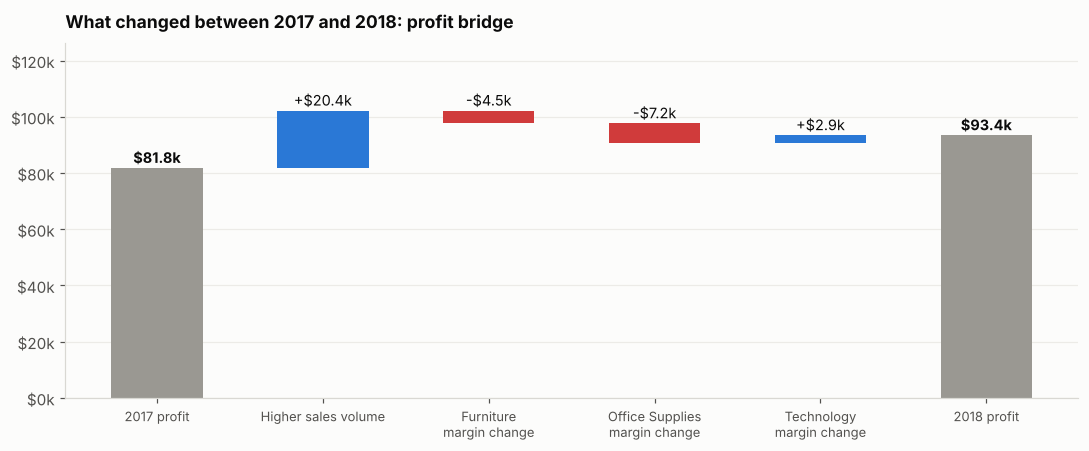

**Finding:** profit rose $11,644 from 2017 to 2018. Higher sales volume added $20,396, but lower margins took back $8,752: Furniture -$4.5k, Office Supplies -$7.2k, Technology +$2.9k. Within the two categories that lost margin, Tables (Furniture) and Binders (Office Supplies), two of the heavily discounted products, each earned less profit in 2018 than in 2017 (-$5.2k and -$2.5k).

In [11]:
fig = L.fig_bridge(T); plt.show()
br = T["bridge"]
sp = d.groupby(["year", "sub_category"])["profit"].sum().unstack(0); sub = sp[br["y2"]] - sp[br["y1"]]
show(f"**Finding:** profit rose {L.money(br['end']-br['start'])} from {br['y1']} to {br['y2']}. Higher sales volume added {L.money(br['volume'])}, but lower margins took back {L.money(-br['rate'].sum())}: "
     + ", ".join(f"{c} {'+' if v > 0 else ''}{L.k(v)}" for c, v in br['rate'].items()) + f". Within the two categories that lost margin, Tables (Furniture) and Binders (Office Supplies), two of the heavily discounted products, each earned less profit in {br['y2']} than in {br['y1']} ({L.k(sub.loc['Tables'])} and {L.k(sub.loc['Binders'])}).")

## 8. Q4: Customers and Segments

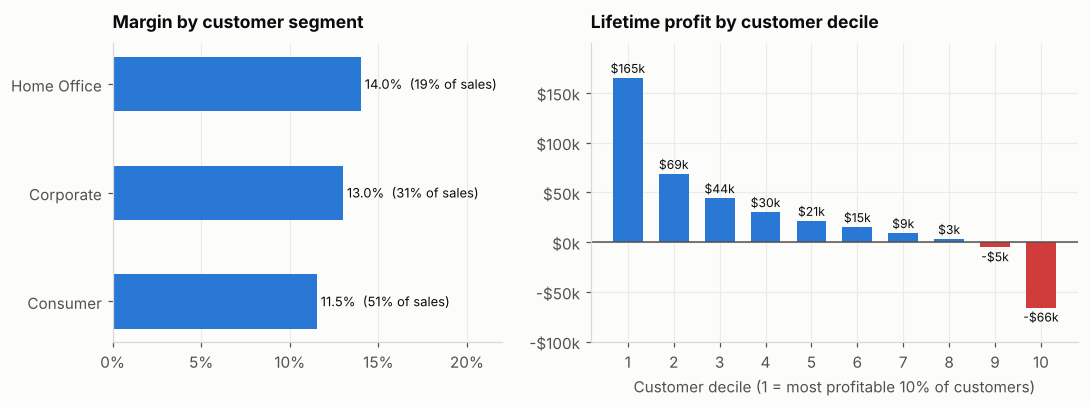

,sales,profit,margin
segment,,,
Consumer,1161401.345,134119.209,0.115
Corporate,706146.367,91979.134,0.130
Home Office,429653.148,60298.678,0.140


**Finding:** customer value is very uneven. The top 10% of customers by sales provide 31% of sales and **43%** of profit. At the other end, **155 customers (20%)** have negative lifetime profit, together losing $71,224, which cancels 20% of the profit earned from all other customers. Segments differ less: Consumer is the largest (51% of sales) but has the lowest margin (11.5%).

In [12]:
fig = L.fig_customers(T); plt.show()
cs = T["cust_stats"]
display(T["segment"][["sales", "profit", "margin"]].round(3))
show(f"**Finding:** customer value is very uneven. The top 10% of customers by sales provide {L.pct(cs['top10_sales_share'],0)} of sales and **{L.pct(cs['top10_profit_share'],0)}** of profit. "
     f"At the other end, **{cs['neg_n']} customers ({L.pct(cs['neg_share'],0)})** have negative lifetime profit, together losing {L.money(-cs['neg_profit'])}, "
     f"which cancels {L.pct(-cs['neg_profit']/cs['pos_profit'],0)} of the profit earned from all other customers. Segments differ less: Consumer is the largest ({L.pct(T['segment'].loc['Consumer','sales']/kp['sales'],0)} of sales) but has the lowest margin ({L.pct(T['segment'].loc['Consumer','margin'])}).")

## 9. Q5a: Seasonality and Shipping

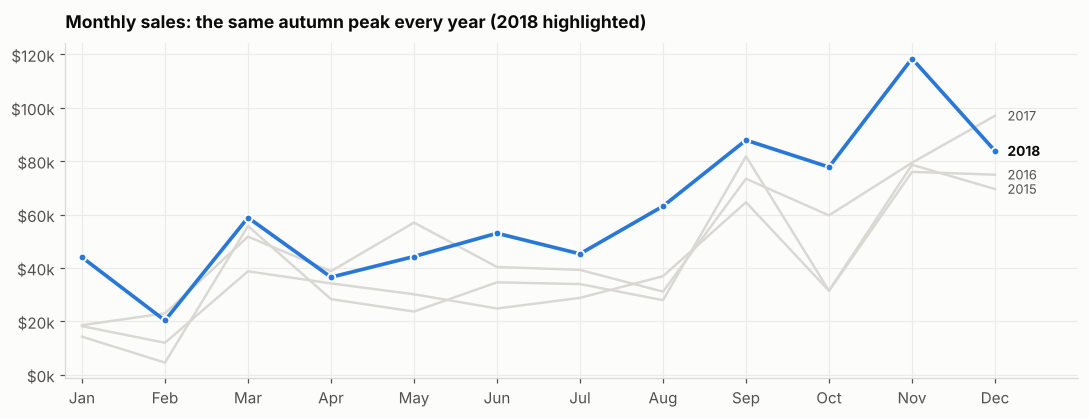

,lines,share_lines,avg_days,margin
ship_mode,,,,
First Class,1538,0.154,2.182,0.139
Same Day,543,0.054,0.044,0.124
Second Class,1945,0.195,3.238,0.125
Standard Class,5968,0.597,5.007,0.121


**Finding:** sales are strongly seasonal and the pattern repeats every year: September to December brings 52% of sales (38% in Q4 alone), with November the peak month, while January and February together bring only 7%. Standard Class carries 60% of lines at about 5 days; margin does not differ much by ship mode (12.1% to 13.9%), so shipping is not a profit driver here.

In [13]:
fig = L.fig_season(T); plt.show()
display(T["ship"][["lines", "share_lines", "avg_days", "margin"]].round(3))
s = T["season"]; months = ["", "January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
show(f"**Finding:** sales are strongly seasonal and the pattern repeats every year: September to December brings {L.pct(s['sepdec'],0)} of sales ({L.pct(s['q4'],0)} in Q4 alone), with {months[s['peak_month']]} the peak month, while January and February together bring only {L.pct(s['janfeb'],0)}. "
     f"Standard Class carries {L.pct(T['ship'].loc['Standard Class','share_lines'],0)} of lines at about {T['ship'].loc['Standard Class','avg_days']:.0f} days; margin does not differ much by ship mode ({L.pct(T['ship']['margin'].min())} to {L.pct(T['ship']['margin'].max())}), so shipping is not a profit driver here.")

## 10. Q5b: Returns

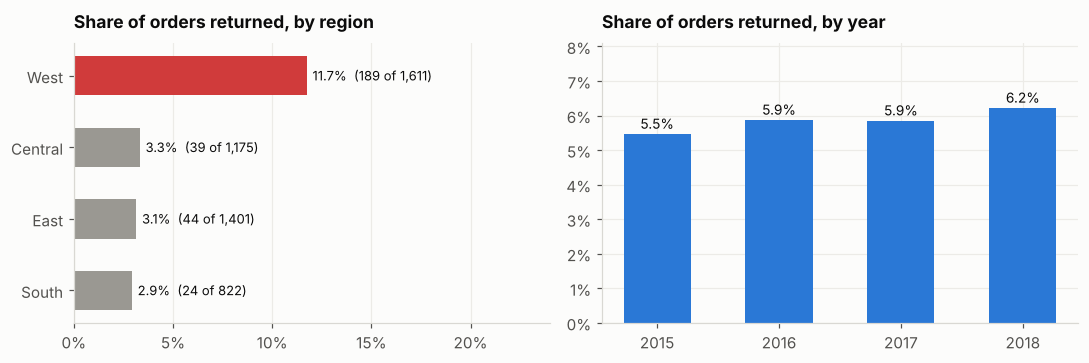

,orders,returned,rate
region,,,
South,822,24,0.029
East,1401,44,0.031
Central,1175,39,0.033
West,1611,189,0.117


**Finding:** 296 of 5,009 orders (5.9%) were returned, covering $180,504 of sales (7.9%). The rate is **11.7% in the West**, roughly four times the 2.9%-3.3% seen in other regions, and it is edging up each year (5.5% in 2015 to 6.2% in 2018). The data has no return reasons or refund amounts, so the cause cannot be determined from it.

In [14]:
fig = L.fig_returns(T); plt.show()
display(T["ret_region"].round(3)); rt = T["ret_total"]
show(f"**Finding:** {rt['orders']} of {kp['orders']:,} orders ({L.pct(rt['rate'])}) were returned, covering {L.money(rt['sales'])} of sales ({L.pct(rt['sales_share'])}). "
     f"The rate is **{L.pct(T['ret_region'].loc['West','rate'])} in the West**, roughly four times the {L.pct(T['ret_region'].drop('West')['rate'].min())}-{L.pct(T['ret_region'].drop('West')['rate'].max())} seen in other regions, and it is edging up each year ({L.pct(T['ret_year']['rate'].iloc[0])} in {T['ret_year'].index[0]} to {L.pct(T['ret_year']['rate'].iloc[-1])} in {T['ret_year'].index[-1]}). "
     f"The data has no return reasons or refund amounts, so the cause cannot be determined from it.")

## 11. What Is the Opportunity Worth? (Scenario)

In [15]:
sb = T["scenario_base"]
sc = T["scenario"].copy()
sc.index = [f"Recover {int(i*100)}% of the loss" for i in sc.index]
sc.columns = ["profit gain", "resulting profit", "profit uplift", "resulting margin"]
show(f"Baseline {sb['year']}: sales {L.money(sb['sales'])}, profit {L.money(sb['profit'])} (margin {L.pct(sb['margin'])}). Heavily discounted lines lost {L.money(-sb['loss'])}.")
display(sc.round(3))
show("**Reading the table:** recovering 100% means those lines break even. **Assumptions:** the sales volume on other lines is unchanged and customers do not leave when discounts are capped. Both are untested, so treat the table as the size of the prize, not a forecast; the 25% row is a cautious planning case.")

Baseline 2018: sales $733,215, profit $93,439 (margin 12.7%). Heavily discounted lines lost $47,570.

,profit gain,resulting profit,profit uplift,resulting margin
Recover 25% of the loss,11892.475,105331.745,0.127,0.144
Recover 50% of the loss,23784.950,117224.220,0.255,0.160
Recover 100% of the loss,47569.900,141009.169,0.509,0.192


**Reading the table:** recovering 100% means those lines break even. **Assumptions:** the sales volume on other lines is unchanged and customers do not leave when discounts are capped. Both are untested, so treat the table as the size of the prize, not a forecast; the 25% row is a cautious planning case.

## 12. Recommendations

In [16]:
recs = pd.DataFrame([
 ["1", "Set discount approval rules: manager sign-off above 20%, finance sign-off above 30%, and a minimum-margin floor per product",
  f"Lines >20% off: {L.pct(T['hd_total']['lines_share'])} of lines, {L.money(-T['hd_total']['profit'])} lost", "High", "Low", "VP Sales / Finance"],
 ["2", "Run a discount review in Central and the loss-making states, starting with Texas, Ohio, Pennsylvania and Illinois",
  f"{len(neg)} states lose {L.money(-neg['profit'].sum())}; Central margin {L.pct(T['region'].loc['Central','margin'])}", "High", "Medium", "Regional sales leaders"],
 ["3", "Put price floors on Tables, Machines and Binders instead of delisting them",
  "Profitable at normal discounts, heavy losses above 20%", "High", "Low", "Category managers"],
 ["4", "Review the terms of the loss-making customers and cap their discounts; protect the top-decile accounts",
  f"{cs['neg_n']} customers lose {L.money(-cs['neg_profit'])}; top 10% give {L.pct(cs['top10_profit_share'],0)} of profit", "Medium", "Medium", "Account management"],
 ["5", "Investigate West returns: add return-reason codes and check products and carriers",
  f"West {L.pct(T['ret_region'].loc['West','rate'])} of orders returned vs about 3% elsewhere", "Medium", "Medium", "Operations"],
 ["6", "Plan stock and staffing for September to December; test margin-safe promotions in January and February",
  f"Sep-Dec = {L.pct(s['sepdec'],0)} of sales; Jan-Feb = {L.pct(s['janfeb'],0)}", "Medium", "Low", "Operations / Marketing"],
 ["7", "Track a monthly scorecard: margin, share of lines >20% off, loss-making lines, return rate by region",
  "Makes the above measurable", "Medium", "Low", "Analytics"],
], columns=["#", "Recommended action", "Evidence", "Impact", "Effort", "Suggested owner"]).set_index("#")
pd.set_option("display.max_colwidth", 90); recs

,Recommended action,Evidence,Impact,Effort,Suggested owner
#,,,,,
1,"Set discount approval rules: manager sign-off above 20%, finance sign-off above 30%, a...","Lines >20% off: 13.9% of lines, $135,376 lost",High,Low,VP Sales / Finance
2,"Run a discount review in Central and the loss-making states, starting with Texas, Ohio...","10 states lose $98,247; Central margin 7.9%",High,Medium,Regional sales leaders
3,"Put price floors on Tables, Machines and Binders instead of delisting them","Profitable at normal discounts, heavy losses above 20%",High,Low,Category managers
4,Review the terms of the loss-making customers and cap their discounts; protect the top...,"155 customers lose $71,224; top 10% give 43% of profit",Medium,Medium,Account management
5,Investigate West returns: add return-reason codes and check products and carriers,West 11.7% of orders returned vs about 3% elsewhere,Medium,Medium,Operations
6,Plan stock and staffing for September to December; test margin-safe promotions in Janu...,Sep-Dec = 52% of sales; Jan-Feb = 7%,Medium,Low,Operations / Marketing
7,"Track a monthly scorecard: margin, share of lines >20% off, loss-making lines, return ...",Makes the above measurable,Medium,Low,Analytics


## 13. Limitations
- The company and data are a **sample dataset** (fictional retailer), so conclusions are illustrative.
- **No cost data**: profit is taken as supplied; the reasons behind individual discounts are unknown, and some deep discounts (clearance, bundles) may be deliberate.
- **Association, not proof**: the data shows heavy discounts and losses occur together; a controlled test is needed to prove that capping discounts will restore profit without losing too many sales.
- The returns list has no dates, reasons or refund amounts, and the scenario assumes unchanged volume.
- State patterns form two clusters, so the strong state-level correlation should be read as "high-discount states lose money", not as a precise rate.

## Appendix: Calculation Code

All tables come from `superstore_lib.tables()`; its source is printed here for transparency.

In [17]:
print(inspect.getsource(L.tables))

def tables(d):
    T = {}
    T["kpi"] = dict(sales=d["sales"].sum(), profit=d["profit"].sum(), margin=d["profit"].sum() / d["sales"].sum(),
                    orders=d["order_id"].nunique(), customers=d["customer_id"].nunique(), lines=len(d),
                    first=d["order_date"].min(), last=d["order_date"].max())
    T["kpi"]["aov"] = T["kpi"]["sales"] / T["kpi"]["orders"]

    y = _agg(d.groupby("year"))
    y["customers"] = d.groupby("year")["customer_id"].nunique()
    y["sales_growth"] = y["sales"].pct_change()
    y["profit_growth"] = y["profit"].pct_change()
    hd = d[d["high_disc"]].groupby("year")
    y["hd_lines"] = hd.size()
    y["hd_lines_share"] = hd.size() / d.groupby("year").size()
    y["hd_sales_share"] = hd["sales"].sum() / y["sales"]
    y["hd_profit"] = hd["profit"].sum()
    y["profit_ex_hd"] = y["profit"] - y["hd_profit"]
    T["yearly"] = y

    T["category"] = _agg(d.groupby("category")).sort_values("profit")
    T["subcat"] = _agg(d.groupby("sub_categor